In [1]:

# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import joblib

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:

import pandas as pd

df = pd.read_csv("/content/spam.csv", encoding="latin-1")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [3]:

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [4]:

df.shape

(5572, 5)

In [5]:

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [6]:

df.isnull().sum()

,0
v1,0
v2,0
Unnamed: 2,5522
Unnamed: 3,5560
Unnamed: 4,5566


In [7]:

df.duplicated().sum()

np.int64(403)

In [8]:

df["v1"].value_counts()

,count
v1,
ham,4825
spam,747


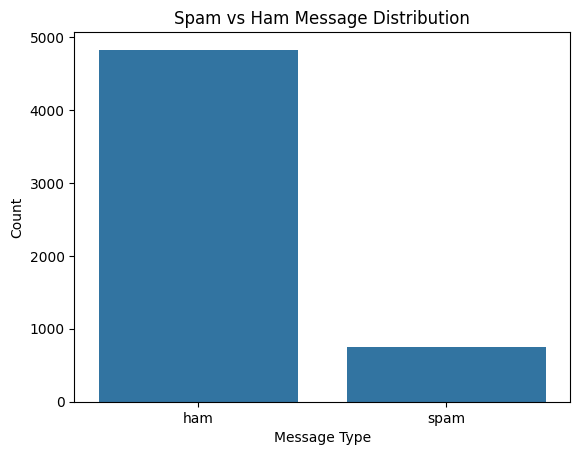

In [9]:

sns.countplot(data=df, x="v1")

plt.title("Spam vs Ham Message Distribution")
plt.xlabel("Message Type")
plt.ylabel("Count")
plt.show()

In [10]:

X = df["v2"]
y = df["v1"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (5572,)
Target shape: (5572,)


In [11]:

# Keep only the required columns
df = df[["v1", "v2"]]

# Remove duplicate rows
df = df.drop_duplicates()

# Reset index
df = df.reset_index(drop=True)

# Separate features and target again
X = df["v2"]
y = df["v1"]

print("Dataset shape after cleaning:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())

Dataset shape after cleaning: (5169, 2)
Duplicate rows remaining: 0


In [12]:

y.value_counts()

,count
v1,
ham,4516
spam,653


In [13]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (4135,)
Testing data: (1034,)
Training labels: (4135,)
Testing labels: (1034,)


In [14]:

# Basic text preprocessing

def preprocess_text(text):
    text = text.lower()
    text = " ".join(text.split())
    return text

# Apply preprocessing
X_train = X_train.apply(preprocess_text)
X_test = X_test.apply(preprocess_text)

print("Original-style message:", X_train.iloc[0])
print("Preprocessed message:", preprocess_text(X_train.iloc[0]))

Original-style message: cool. so how come you havent been wined and dined before?
Preprocessed message: cool. so how come you havent been wined and dined before?


In [15]:

from sklearn.feature_extraction.text import CountVectorizer

# Small example
messages = [
    "I love machine learning",
    "I love Python",
    "Python is amazing"
]

vectorizer_demo = CountVectorizer()

demo_matrix = vectorizer_demo.fit_transform(messages)

print("Vocabulary:")
print(vectorizer_demo.get_feature_names_out())

print("\nFeature Matrix:")
print(demo_matrix.toarray())

Vocabulary:
['amazing' 'is' 'learning' 'love' 'machine' 'python']

Feature Matrix:
[[0 0 1 1 1 0]
 [0 0 0 1 0 1]
 [1 1 0 0 0 1]]


In [16]:

vectorizer = CountVectorizer()

X_train_vectorized = vectorizer.fit_transform(X_train)
X_test_vectorized = vectorizer.transform(X_test)

print("Training feature matrix:", X_train_vectorized.shape)
print("Testing feature matrix:", X_test_vectorized.shape)
print("Total vocabulary words:", len(vectorizer.vocabulary_))

Training feature matrix: (4135, 7591)
Testing feature matrix: (1034, 7591)
Total vocabulary words: 7591


In [17]:

# Import Multinomial Naive Bayes
from sklearn.naive_bayes import MultinomialNB

# Create the model
nb_model = MultinomialNB()

# Train the model
nb_model.fit(X_train_vectorized, y_train)

print("Multinomial Naive Bayes model trained successfully!")

Multinomial Naive Bayes model trained successfully!


In [18]:

# Make predictions
y_pred_nb = nb_model.predict(X_test_vectorized)

# Display first 10 predictions
print("Predicted labels:", y_pred_nb[:10])
print("Actual labels:   ", y_test.iloc[:10].values)

Predicted labels: ['ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham']
Actual labels:    ['ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham']


In [19]:

accuracy = accuracy_score(y_test, y_pred_nb)

precision = precision_score(
    y_test, y_pred_nb, pos_label="spam"
)

recall = recall_score(
    y_test, y_pred_nb, pos_label="spam"
)

f1 = f1_score(
    y_test, y_pred_nb, pos_label="spam"
)

print("Naive Bayes Evaluation")
print("----------------------")
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))

Naive Bayes Evaluation
----------------------
Accuracy : 0.9865
Precision: 0.9756
Recall   : 0.916
F1-score : 0.9449


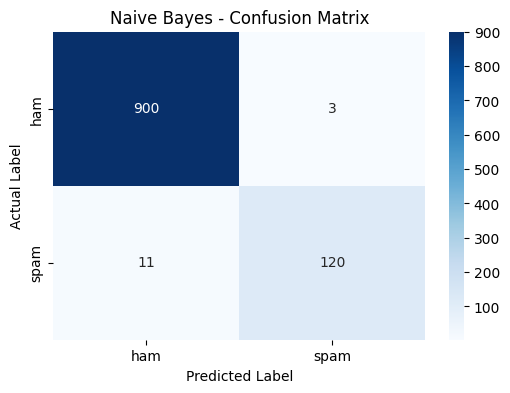

Confusion Matrix:
[[900   3]
 [ 11 120]]


In [20]:

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    y_pred_nb,
    labels=["ham", "spam"]
)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["ham", "spam"],
    yticklabels=["ham", "spam"]
)

plt.title("Naive Bayes - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

print("Confusion Matrix:")
print(cm)

In [21]:

print(classification_report(y_test, y_pred_nb))

              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       903
        spam       0.98      0.92      0.94       131

    accuracy                           0.99      1034
   macro avg       0.98      0.96      0.97      1034
weighted avg       0.99      0.99      0.99      1034



In [22]:

# Train the Logistic Regression model

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_vectorized, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [23]:

# Make predictions using Logistic Regression

y_pred_lr = lr_model.predict(X_test_vectorized)

print("First 10 predicted labels:", y_pred_lr[:10])
print("First 10 actual labels:   ", y_test.iloc[:10].values)

First 10 predicted labels: ['ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham']
First 10 actual labels:    ['ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham' 'ham']


In [24]:

# Evaluate Logistic Regression

accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr, pos_label="spam")
recall_lr = recall_score(y_test, y_pred_lr, pos_label="spam")
f1_lr = f1_score(y_test, y_pred_lr, pos_label="spam")

print("Logistic Regression Model Evaluation")
print("------------------------------------")
print(f"Accuracy:  {accuracy_lr:.4f}")
print(f"Precision: {precision_lr:.4f}")
print(f"Recall:    {recall_lr:.4f}")
print(f"F1-score:  {f1_lr:.4f}")

Logistic Regression Model Evaluation
------------------------------------
Accuracy:  0.9797
Precision: 0.9911
Recall:    0.8473
F1-score:  0.9136


In [25]:

# Test custom SMS messages

custom_messages = [
    "Congratulations! You have won a free prize. Call now!",
    "Hey, are we meeting today?",
    "URGENT! You have won a cash reward. Claim now!",
    "Can you please send me the homework?"
]

# Apply the same preprocessing used during training
custom_messages_cleaned = [
    preprocess_text(message) for message in custom_messages
]

# Convert messages into Bag of Words features
custom_messages_vectorized = vectorizer.transform(
    custom_messages_cleaned
)

# Predict using our selected model
custom_predictions = nb_model.predict(custom_messages_vectorized)

# Display the results
for message, prediction in zip(custom_messages, custom_predictions):
    print(f"Message: {message}")
    print(f"Prediction: {prediction.upper()}")
    print("-" * 50)


Message: Congratulations! You have won a free prize. Call now!
Prediction: SPAM
--------------------------------------------------
Message: Hey, are we meeting today?
Prediction: HAM
--------------------------------------------------
Message: URGENT! You have won a cash reward. Claim now!
Prediction: SPAM
--------------------------------------------------
Message: Can you please send me the homework?
Prediction: HAM
--------------------------------------------------


In [26]:

# Save the trained model and vectorizer

joblib.dump(nb_model, "spam_nb_model.pkl")
joblib.dump(vectorizer, "spam_vectorizer.pkl")

print("Model saved as: spam_nb_model.pkl")
print("Vectorizer saved as: spam_vectorizer.pkl")

Model saved as: spam_nb_model.pkl
Vectorizer saved as: spam_vectorizer.pkl


In [27]:

# Load the saved model and vectorizer

loaded_model = joblib.load("spam_nb_model.pkl")
loaded_vectorizer = joblib.load("spam_vectorizer.pkl")

# Test a new message
new_message = ["You have won a free gift! Claim it now."]

# Apply preprocessing and vectorization
new_message_cleaned = [
    preprocess_text(message) for message in new_message
]
new_message_vectorized = loaded_vectorizer.transform(
    new_message_cleaned
)

# Predict the message category
prediction = loaded_model.predict(new_message_vectorized)

print("SMS:", new_message[0])
print("Predicted category:", prediction[0].upper())


SMS: You have won a free gift! Claim it now.
Predicted category: SPAM
